# Workshop 1 — ZOOM IN IMAGES
 - **Student:** Francesc Serra Crespí
 - **Email:** francesc.serra-crespi@universite-paris-saclay.fr
 - **Master Program:** M2 AI

In [36]:
# 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
import cv2

Load image 

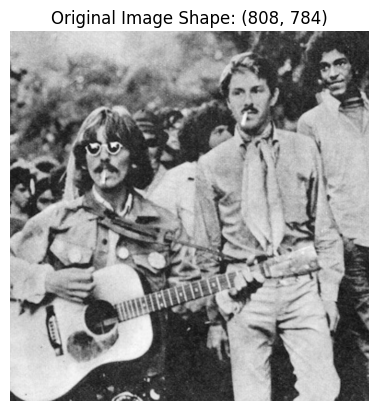

,Sampling Frequency,Nyquist Frequency
Horizontal X,1,0.5
Vertical Y,1,0.5


In [37]:
# 1. Load image 
image_data=cv2.imread('data/img_try.png', cv2.IMREAD_GRAYSCALE)
plt.imshow(image_data, cmap='gray')
plt.title(f"Original Image Shape: {image_data.shape}")
plt.axis("off")
plt.show()

# For the original data what we have is an dx and dy of 1 pixel
# The frequency of sampling is 1.
# F Nysquist = Fs/2 = 0.5 cycles per pixel
# as a result the frequency domain will be in cycles per pixel and the Frequency of Nyquist will be 0.5 cycles per pixel. 
# The frequency domain will be in the range of -0.5 to 0.5 cycles per pixel.

# Sampling frequency in pixels
Fs_x = 1  
Fs_y = 1 
# Nyquist frequency in cycles per pixel
Fn_x = Fs_x / 2  
Fn_y = Fs_y / 2  

display(pd.DataFrame([(Fs_x,Fn_x), (Fs_y,Fn_y)], columns=['Sampling Frequency', 'Nyquist Frequency']).set_index(pd.Index(['Horizontal X', 'Vertical Y'])))



In [38]:
# Filters 

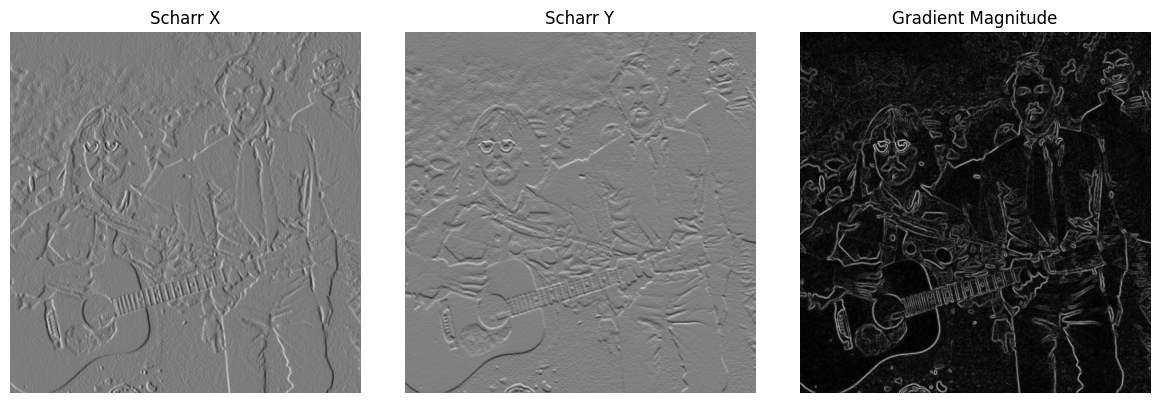

In [39]:
# 1. Gradient filter -> cv2.Scharr()
grad_x = cv2.Scharr(image_data, cv2.CV_64F, 1, 0)
grad_y = cv2.Scharr(image_data, cv2.CV_64F, 0, 1)

gradient_magnitude = np.sqrt(grad_x**2 + grad_y**2)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(grad_x, cmap='gray')
plt.title("Scharr X")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(grad_y, cmap='gray')
plt.title("Scharr Y")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gradient_magnitude, cmap='gray')
plt.title("Gradient Magnitude")
plt.axis("off")

plt.tight_layout()
plt.show()

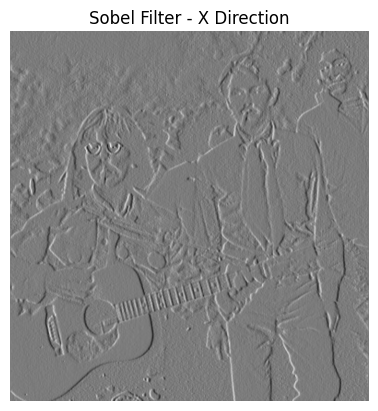

(np.float64(-0.5), np.float64(783.5), np.float64(807.5), np.float64(-0.5))

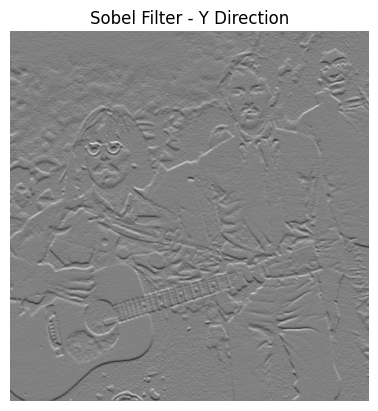

In [40]:
# 2. Sobel filter -> cv2.Sobel()
sobel_x = cv2.Sobel(image_data, cv2.CV_64F, 1, 0)
sobel_y = cv2.Sobel(image_data, cv2.CV_64F, 0, 1)

plt.imshow(sobel_x, cmap='gray')
plt.title("Sobel Filter - X Direction")
plt.axis("off")
plt.show()

plt.imshow(sobel_y, cmap='gray')
plt.title("Sobel Filter - Y Direction")
plt.axis("off")

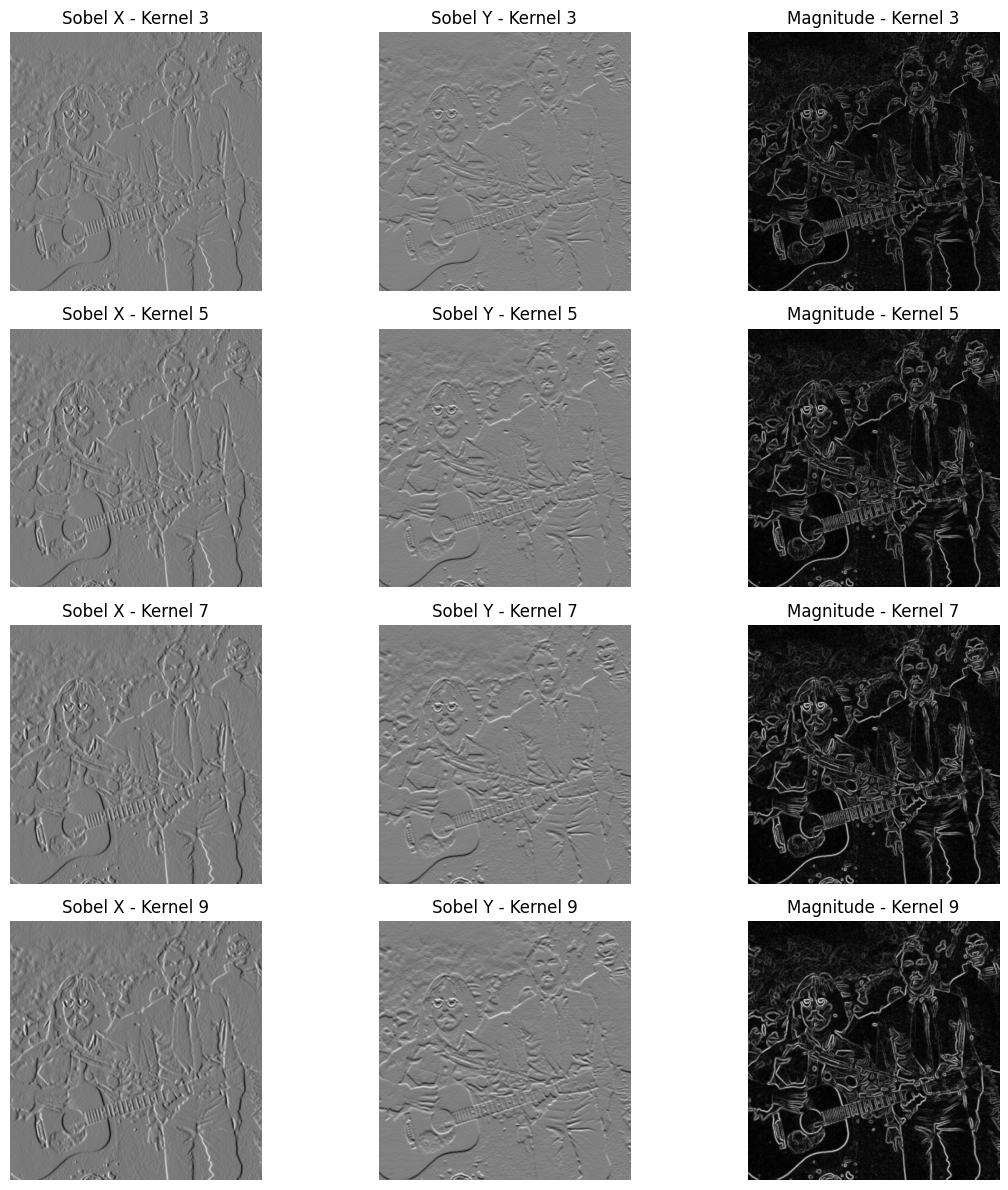

In [41]:
kernel_sizes = [3, 5, 7, 9]

plt.figure(figsize=(12, 12))

for i, kernel in enumerate(kernel_sizes):
    sobel_x = cv2.Sobel(image_data, cv2.CV_64F, 1, 0, ksize=kernel)
    sobel_y = cv2.Sobel(image_data, cv2.CV_64F, 0, 1, ksize=kernel)

    magnitude = np.sqrt(sobel_x**2 + sobel_y**2)

    plt.subplot(len(kernel_sizes), 3, i * 3 + 1)
    plt.imshow(sobel_x, cmap='gray')
    plt.title(f"Sobel X - Kernel {kernel}")
    plt.axis("off")

    plt.subplot(len(kernel_sizes), 3, i * 3 + 2)
    plt.imshow(sobel_y, cmap='gray')
    plt.title(f"Sobel Y - Kernel {kernel}")
    plt.axis("off")

    plt.subplot(len(kernel_sizes), 3, i * 3 + 3)
    plt.imshow(magnitude, cmap='gray')
    plt.title(f"Magnitude - Kernel {kernel}")
    plt.axis("off")

plt.tight_layout()
plt.show()

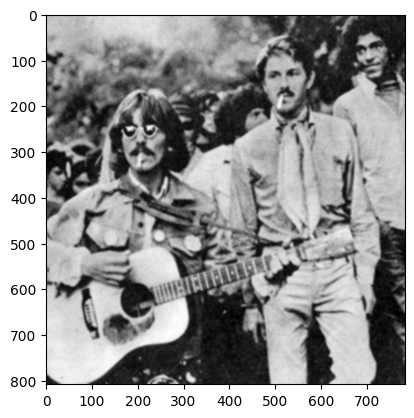

In [42]:
# 3. Averaging filter -> cv2.blur()
average = cv2.blur(image_data, (5, 5))
plt.imshow(average, cmap='gray')


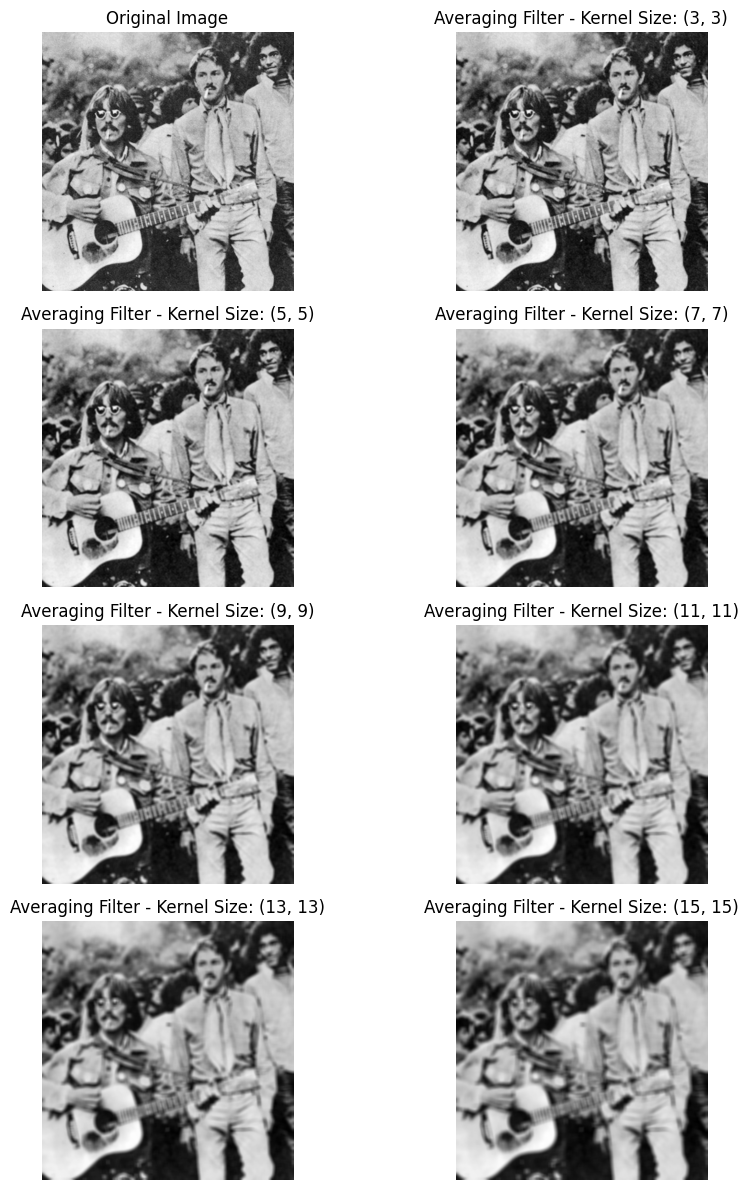

In [43]:
list_of_kernels = [(3, 3), (5, 5), (7, 7), (9, 9), (11, 11), (13, 13), (15, 15)]

plt.figure(figsize=(10, 12))

plt.subplot(4, 2, 1)
plt.imshow(image_data, cmap='gray')
plt.title("Original Image")
plt.axis("off")

for i, kernel in enumerate(list_of_kernels):
    average = cv2.blur(image_data, kernel)

    plt.subplot(4, 2, i + 2)
    plt.imshow(average, cmap='gray')
    plt.title(f"Averaging Filter - Kernel Size: {kernel}")
    plt.axis("off")

plt.tight_layout()
plt.show()


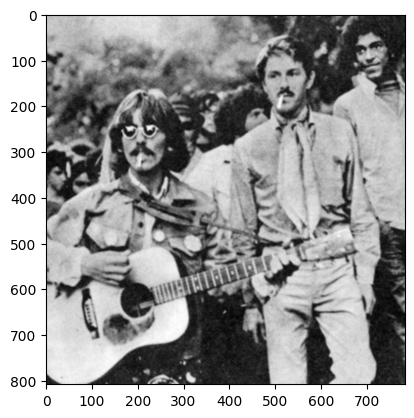

In [44]:
# 4. Gaussian filter -> cv2.GaussianBlur()
gaussian = cv2.GaussianBlur(image_data, (5, 5), 1)
plt.imshow(gaussian, cmap='gray')

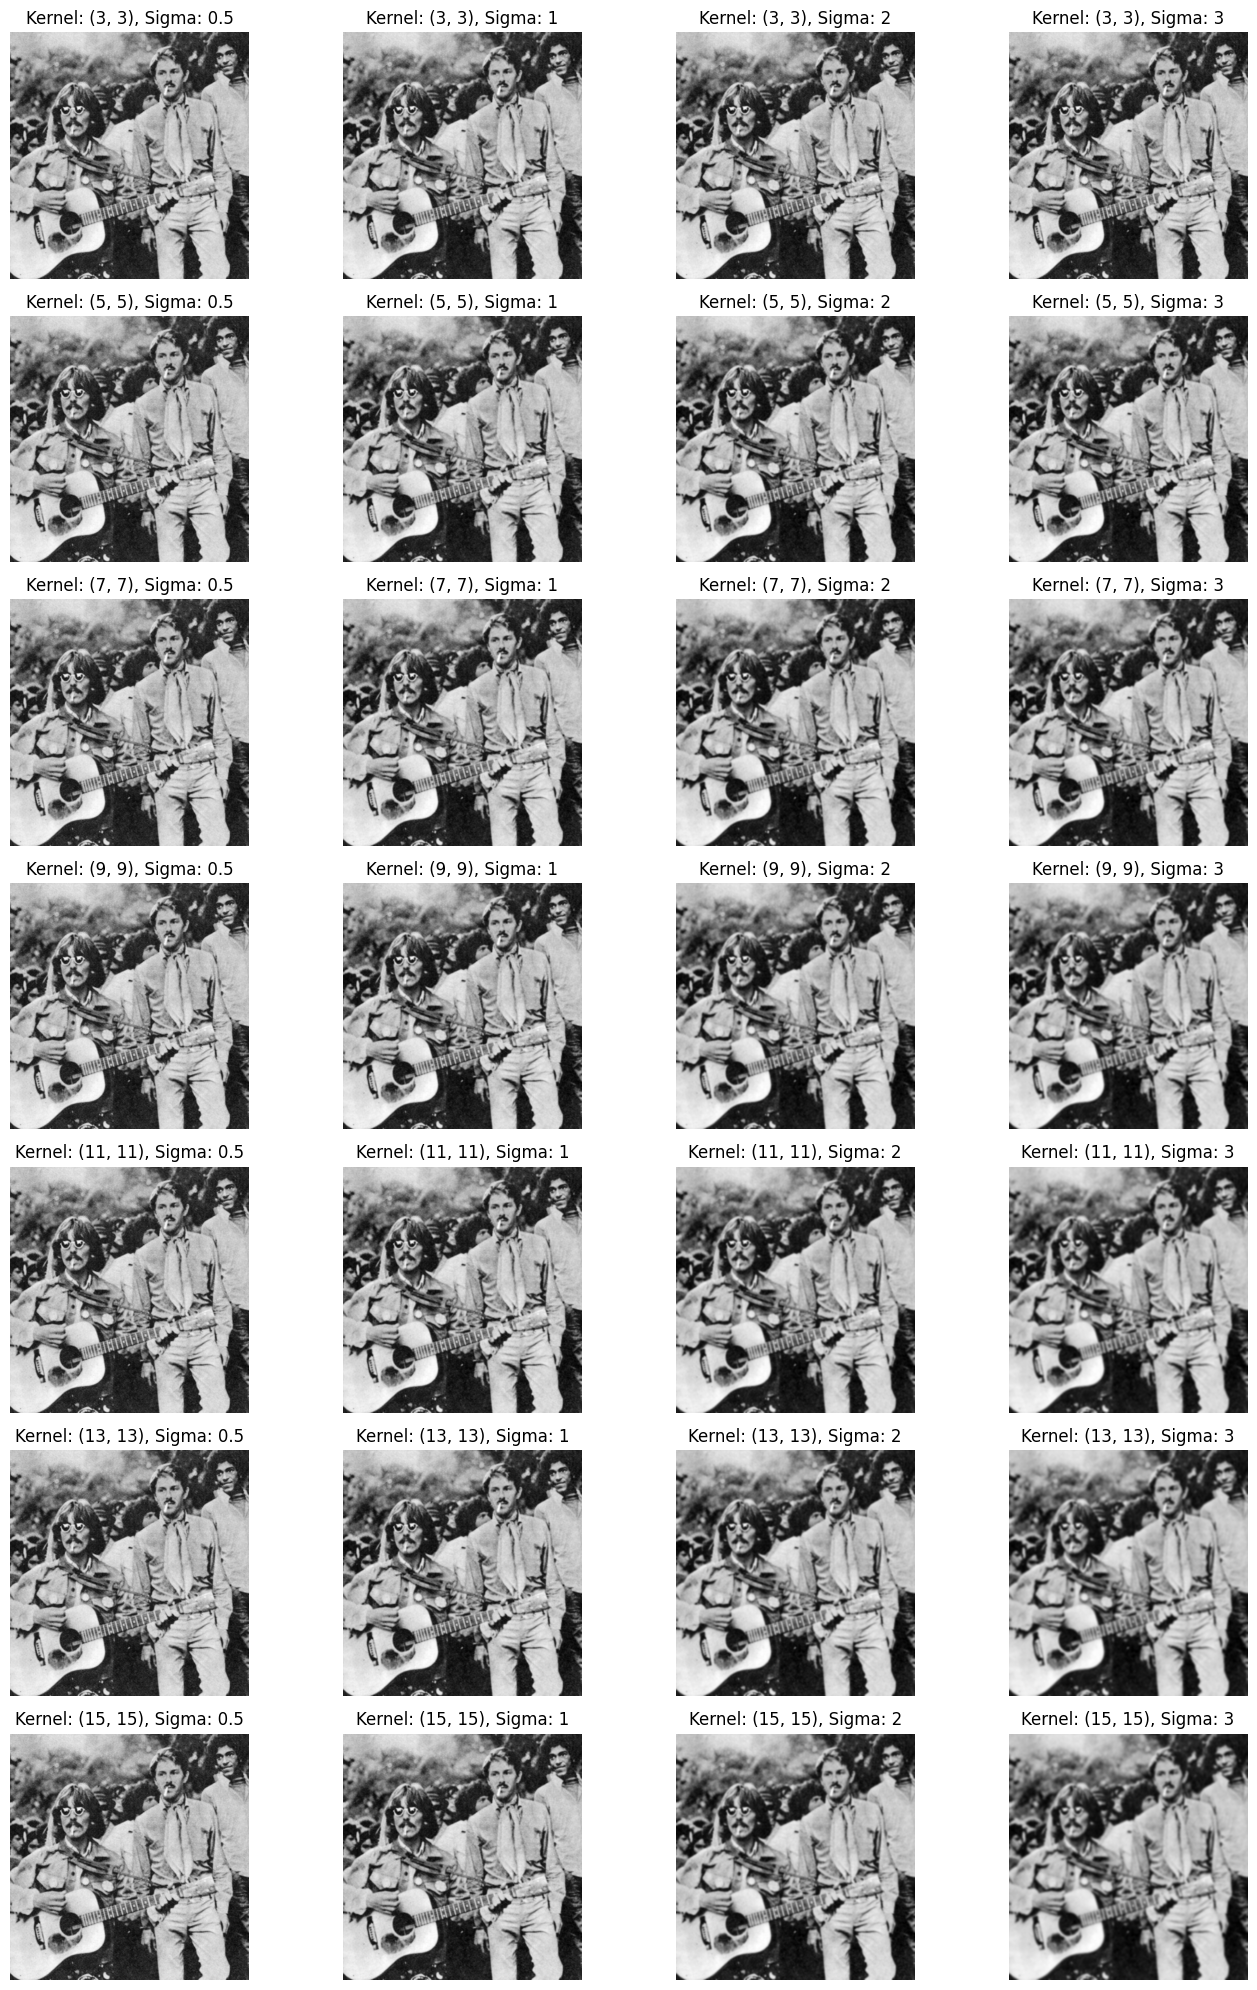

In [45]:
sigma_values = [0.5, 1, 2, 3]

plt.figure(figsize=(14, 20))

for i, kernel in enumerate(list_of_kernels):
    for j, sigma in enumerate(sigma_values):
        gaussian = cv2.GaussianBlur(image_data, kernel, sigma)

        plt.subplot(
            len(list_of_kernels),
            len(sigma_values),
            i * len(sigma_values) + j + 1
        )

        plt.imshow(gaussian, cmap='gray')
        plt.title(f"Kernel: {kernel}, Sigma: {sigma}")
        plt.axis("off")

plt.tight_layout()
plt.show()